# KPIs a partir de video

In [47]:
# cargar dataframes de /dataframes
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from rapidfuzz import fuzz

import os
from openai import OpenAI


per_track = pd.read_csv("dataframes/person_tracking_csic.tsv", sep="\t", encoding="utf-8")
ocr = pd.read_csv("dataframes/ocr_csic.tsv", sep="\t", encoding="utf-8")

## Person tracking

por persona
- centralidad media por persona
- area media por persona
- tiempo total en pantalla por persona

por género (agregar)
- centralidad media por género
- area media por género
- porcentajes de tiempo total

In [26]:
per_track.head()

,frames,area,centrality,screen_time_s,gender,gender_mivolo,person,gender_person,start_s,end_s
0,67,0.692005,0.715968,10.72,unknown,M,10,M,0.12,10.68
1,43,0.547739,0.902055,6.88,M,M,6,M,10.84,17.56
2,19,0.393157,0.947308,3.04,M,M,6,M,23.32,26.20
3,44,0.165247,0.814611,7.04,F,F,5,F,26.36,33.24
4,43,0.395572,0.667293,6.88,M,M,1,M,26.52,33.24


### Por persona

In [27]:
agg_per_track = per_track.groupby("person").agg({"centrality":"mean", "area":"mean", "screen_time_s":"sum", "gender_person":"first"}).sort_values(["screen_time_s", "area", "centrality"], ascending=False).head(10)
agg_per_track

,centrality,area,screen_time_s,gender_person
person,,,,
8,0.748263,0.310982,38.40,M
4,0.642036,0.319418,23.20,F
5,0.800586,0.170342,12.32,F
9,0.821867,0.658426,12.00,unknown
1,0.574723,0.352950,12.00,M
6,0.916312,0.473253,11.36,M
10,0.715968,0.692005,10.72,M
2,0.391579,0.286326,4.48,M
3,0.471453,0.325666,2.88,M


<Axes: xlabel='person', ylabel='centrality'>

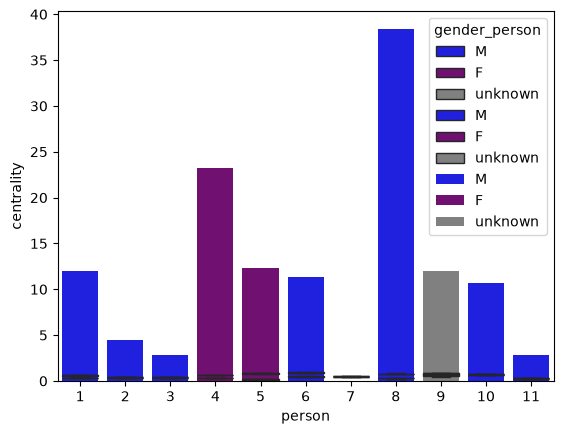

In [28]:
# gráfico: tres gráficos uno al lado del otro, en horizontal: 1. boxplot centralidad por persona, 2. boxpot area ocupada por persona, 3. gráfico de barras: tiempo total
# colores: unknown en gris, mujer en morado, hombre azul
sns.boxplot(data=per_track, x="person", y="centrality", hue="gender_person", palette={"unknown":"gray", "F":"purple", "M":"blue"})
sns.boxplot(data=per_track, x="person", y="area", hue="gender_person", palette={"unknown":"gray", "F":"purple", "M":"blue"})
sns.barplot(data=agg_per_track.reset_index(), x="person", y="screen_time_s", hue="gender_person", palette={"unknown":"gray", "F":"purple", "M":"blue"})


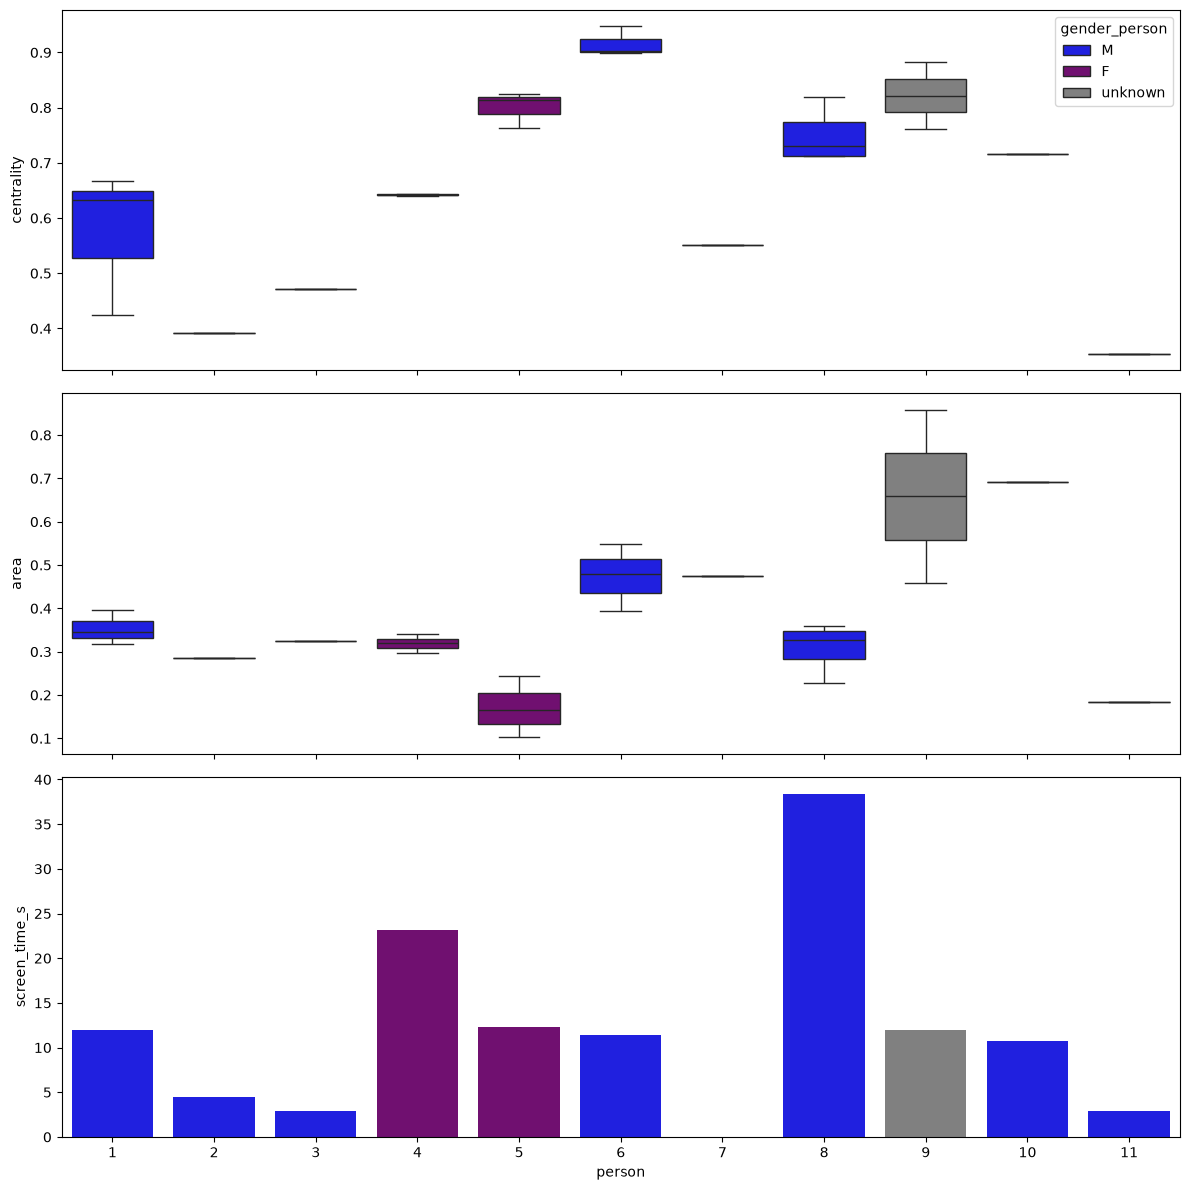

In [29]:
PALETTE = {"unknown": "gray", "F": "purple", "M": "blue"}
order = sorted(per_track.person.unique())       # mismo orden de personas en los 3 gráficos

fig, axes = plt.subplots(3, 1, figsize=(12, 12), sharex=True)   # 3 filas, 1 columna
sns.boxplot(data=per_track, x="person", y="centrality", hue="gender_person",
            palette=PALETTE, order=order, dodge=False, ax=axes[0])
sns.boxplot(data=per_track, x="person", y="area", hue="gender_person",
            palette=PALETTE, order=order, dodge=False, ax=axes[1])
sns.barplot(data=agg_per_track.reset_index(), x="person", y="screen_time_s", hue="gender_person",
            palette=PALETTE, order=order, dodge=False, ax=axes[2])

for ax in axes[1:]:
    ax.get_legend().remove()                    # una sola leyenda, en el primer gráfico
plt.tight_layout()
plt.show()


### Agregados por género inferido

In [30]:
agg_gender = per_track.groupby("gender_person").agg({"centrality":"mean", "area":"mean", "screen_time_s":"sum"}).sort_values(["screen_time_s", "area", "centrality"], ascending=False).head(10)
agg_gender

,centrality,area,screen_time_s
gender_person,,,
M,0.673294,0.371051,85.12
F,0.737166,0.229972,35.52
unknown,0.821867,0.658426,12.00


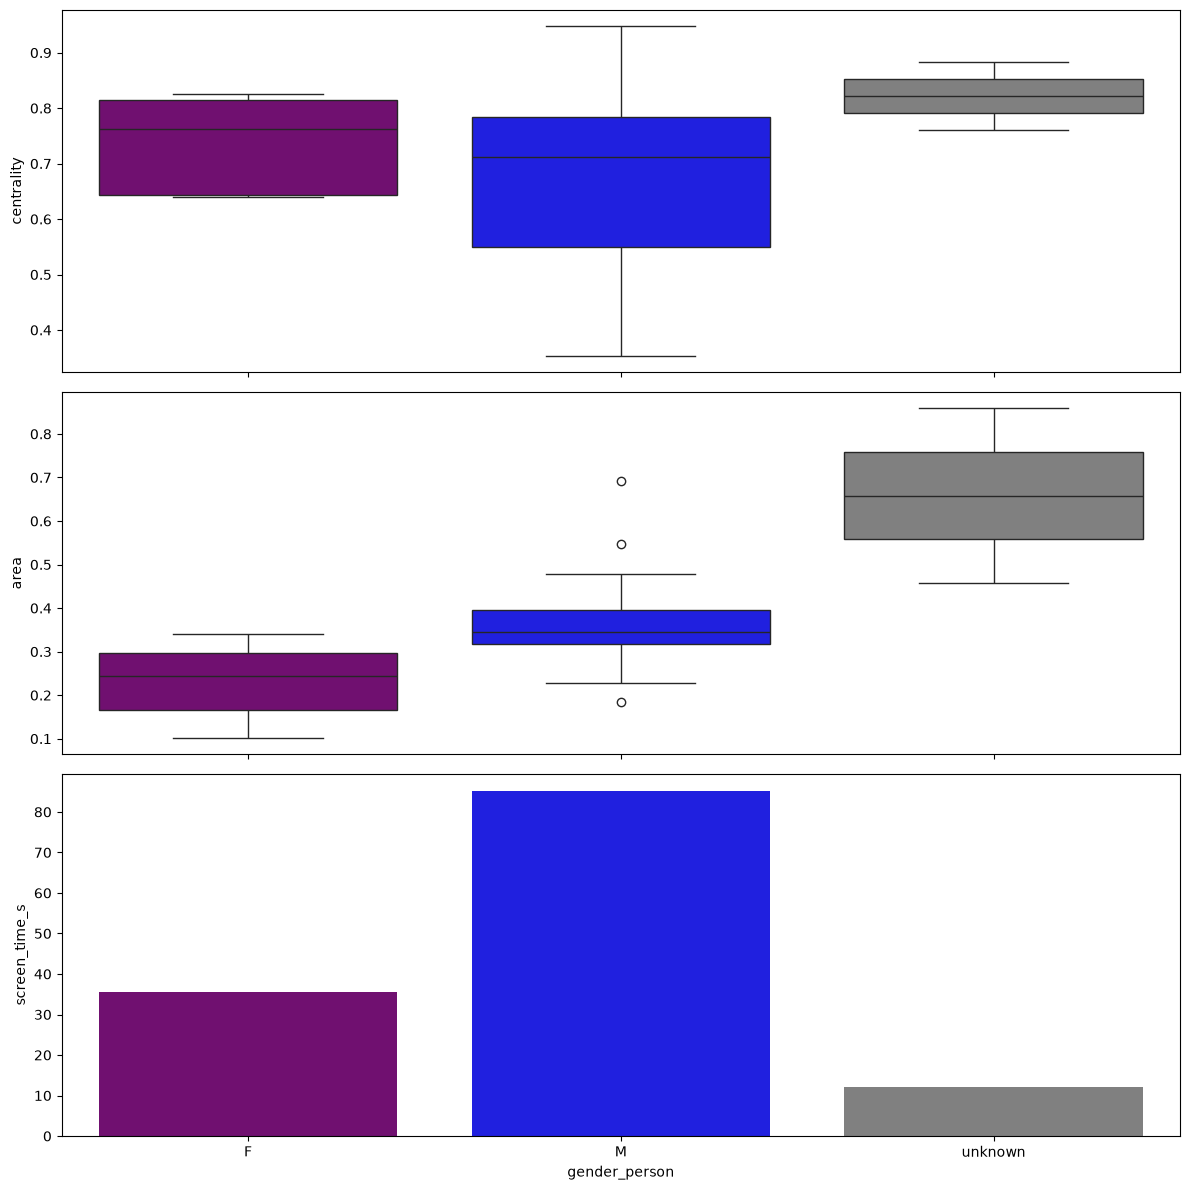

In [31]:
# gráfico: tres gráficos uno al lado del otro, en horizontal: 1. boxplot centralidad por género, 2. boxpot area ocupada por género, 3. gráfico de barras: porcentaje total del tiempo del video por género
# colores: unknown en gris, mujer en morado, hombre azul

PALETTE = {"unknown": "gray", "F": "purple", "M": "blue"}
order = sorted(per_track.gender_person.unique())       # mismo orden de personas en los 3 gráficos

fig, axes = plt.subplots(3, 1, figsize=(12, 12), sharex=True)   # 3 filas, 1 columna
sns.boxplot(data=per_track, x="gender_person", y="centrality", hue="gender_person",
            palette=PALETTE, order=order, dodge=False, ax=axes[0])
sns.boxplot(data=per_track, x="gender_person", y="area", hue="gender_person",
            palette=PALETTE, order=order, dodge=False, ax=axes[1])
sns.barplot(data=agg_gender.reset_index(), x="gender_person", y="screen_time_s", hue="gender_person",
            palette=PALETTE, order=order, dodge=False, ax=axes[2])

# for ax in axes[1:]:
#     ax.get_legend().remove()                    # una sola leyenda, en el primer gráfico
plt.tight_layout()
plt.show()

gender_person
F          26.8
M          64.2
unknown     9.0
Name: screen_time_s, dtype: float64


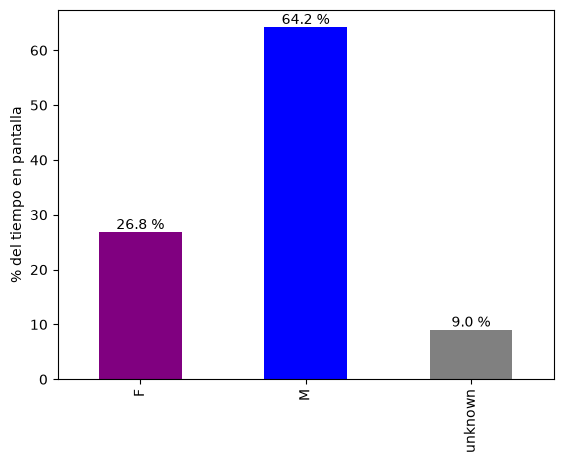

In [32]:

# % del tiempo total en pantalla de cada género
share = per_track.groupby("gender_person").screen_time_s.sum()
pct = (100 * share / share.sum()).round(1)
print(pct)

ax = pct.plot.bar(color=[PALETTE[g] for g in pct.index])
ax.bar_label(ax.containers[0], fmt="%.1f %%")    # pone el % encima de cada barra
ax.set_ylabel("% del tiempo en pantalla"); ax.set_xlabel("")
plt.show()


Interpretación:
- Centralidad horizontal (1,0): 0 si está pegada a uno de los bordes, 1 si está en el centro de la imagen
- Area (1,0): proporción total de la imagen (promediado por todos los frames del track)
- total screen time

## OCR

In [38]:
ocr.head()
ocr.info()

<class 'pandas.DataFrame'>
RangeIndex: 51 entries, 0 to 50
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   frame   51 non-null     int64  
 1   t       51 non-null     float64
 2   text    51 non-null     str    
 3   conf    51 non-null     float64
 4   box     51 non-null     str    
 5   x       51 non-null     float64
 6   y       51 non-null     float64
dtypes: float64(4), int64(1), str(2)
memory usage: 2.9 KB


In [42]:
SIM = 90   # similitud mínima (0-100) para considerar que dos lecturas son el mismo texto

# 1) Agrupar variantes de lectura. Recorremos de más a menos frecuente para que la variante más leída sea la canónica
canon, mapping = [], {}
for text in ocr.text.value_counts().index:
    match = next((c for c in canon if fuzz.ratio(text.lower(), c.lower()) >= SIM), None)
    if match is None:
        canon.append(text); match = text
    mapping[text] = match
ocr["text_dedup"] = ocr.text.map(mapping)

# 2) Una fila por texto único: cuándo aparece y con qué confianza media
texts = (ocr.groupby("text_dedup")
            .agg(start_s=("t", "min"), end_s=("t", "max"), n_frames=("frame", "nunique"), conf=("conf", "mean"))
            .sort_values("start_s").round(2))
texts


,start_s,end_s,n_frames,conf
text_dedup,,,,
David Ríos Insua,12.0,16.0,5,0.76
Investigador del ICMAT,13.0,16.0,4,0.79
ô,39.0,39.0,1,0.79
0,43.0,43.0,1,1.00
Juan Antonio Rodríguez,48.0,52.0,5,0.94
Investigador en el IIIA,48.0,52.0,5,0.79
CSIC,51.0,149.0,6,0.90
ôô,69.0,69.0,1,1.00
ô_ô,70.0,70.0,1,0.57


In [44]:
MAX_GAP = 3   # segundos sin ver un texto a partir de los cuales la siguiente lectura es otra aparición

# 2) Partir cada texto en apariciones: empieza una nueva cuando pasan más de MAX_GAP s desde la lectura anterior
ocr = ocr.sort_values(["text_dedup", "t"])
ocr["appearance"] = ocr.groupby("text_dedup").t.transform(lambda t: (t.diff() > MAX_GAP).cumsum())

# 3) Una fila por aparición: texto, cuándo empieza y acaba, y con qué confianza media
texts = (ocr.groupby(["text_dedup", "appearance"])
            .agg(start_s=("t", "min"), end_s=("t", "max"), n_frames=("frame", "nunique"), conf=("conf", "mean"))
            .reset_index().drop(columns="appearance")
            .sort_values("start_s").round(2))
texts


,text_dedup,start_s,end_s,n_frames,conf
3,David Ríos Insua,12.0,16.0,5,0.76
6,Investigador del ICMAT,13.0,16.0,4,0.79
14,ô,39.0,39.0,1,0.79
0,0,43.0,43.0,1,1.00
8,Juan Antonio Rodríguez,48.0,52.0,5,0.94
7,Investigador en el IIIA,48.0,52.0,5,0.79
1,CSIC,51.0,51.0,1,0.41
16,ôô,69.0,69.0,1,1.00
15,ô_ô,70.0,70.0,1,0.57
12,iCorrecto!,72.0,73.0,2,0.64


In [67]:
# OVH AI Endpoints es compatible con la API de OpenAI: solo cambian la URL, la clave y el modelo

client = OpenAI(base_url="https://oai.endpoints.kepler.ai.cloud.ovh.net/v1",                 # <- placeholder
                api_key=os.environ["OVH_AI_ENDPOINTS_ACCESS_TOKEN"])      # <- placeholder

MODEL = "Meta-Llama-3_3-70B-Instruct"                                       # <- placeholder

PROMPT = """Te paso un texto leído por OCR en un vídeo. Puede tener errores de lectura y estar en español, catalán o inglés.
Responde solo "true" si es el nombre propio de una persona o el cargo, profesión o afiliación de una persona
(por ejemplo "catedràtica de la UPC").
Responde solo "false" en cualquier otro caso: logos, marcas, texto de la escena, palabras sueltas o lecturas sin sentido.
Texto: {text}"""

def is_name_or_role(text):
    resp = client.chat.completions.create(
        model=MODEL, temperature=0,             # temperature=0: misma respuesta cada vez
        messages=[{"role": "user", "content": PROMPT.format(text=text)}])
    print(resp)
    return resp.choices[0].message.content.strip().lower().startswith("true")

# Una llamada por texto único (no por fila) y repartimos el resultado a todas sus apariciones
is_relevant = {t: is_name_or_role(t) for t in texts.text_dedup.unique()}

texts["is_name_or_role"] = texts.text_dedup.map(is_relevant)
display(texts)
texts = texts[texts.is_name_or_role]


ChatCompletion(id='chatcmpl-992b7810db75b27d', choices=[Choice(finish_reason='stop', index=0, logprobs=None, message=ChatCompletionMessage(content='true', refusal=None, role='assistant', annotations=None, audio=None, function_call=None, tool_calls=[]))], created=1792601595, model='Meta-Llama-3_3-70B-Instruct', object='chat.completion', metadata=None, moderation=None, service_tier=None, system_fingerprint=None, usage=CompletionUsage(completion_tokens=2, prompt_tokens=146, total_tokens=148, completion_tokens_details=None, prompt_tokens_details=None))
ChatCompletion(id='chatcmpl-843d69e2b3650d50', choices=[Choice(finish_reason='stop', index=0, logprobs=None, message=ChatCompletionMessage(content='true', refusal=None, role='assistant', annotations=None, audio=None, function_call=None, tool_calls=[]))], created=1792601595, model='Meta-Llama-3_3-70B-Instruct', object='chat.completion', metadata=None, moderation=None, service_tier=None, system_fingerprint=None, usage=CompletionUsage(completio

,text_dedup,start_s,end_s,n_frames,conf,is_name_or_role
3,David Ríos Insua,12.0,16.0,5,0.76,True
6,Investigador del ICMAT,13.0,16.0,4,0.79,True
14,ô,39.0,39.0,1,0.79,False
0,0,43.0,43.0,1,1.00,False
8,Juan Antonio Rodríguez,48.0,52.0,5,0.94,True
7,Investigador en el IIIA,48.0,52.0,5,0.79,True
1,CSIC,51.0,51.0,1,0.41,False
16,ôô,69.0,69.0,1,1.00,False
15,ô_ô,70.0,70.0,1,0.57,False
12,iCorrecto!,72.0,73.0,2,0.64,False


In [68]:
texts

,text_dedup,start_s,end_s,n_frames,conf,is_name_or_role
3,David Ríos Insua,12.0,16.0,5,0.76,True
6,Investigador del ICMAT,13.0,16.0,4,0.79,True
8,Juan Antonio Rodríguez,48.0,52.0,5,0.94,True
7,Investigador en el IIIA,48.0,52.0,5,0.79,True
11,Sandra Freire,114.0,118.0,5,0.96,True
10,Pedagoga en Deletrea,115.0,118.0,4,0.90,True


## Cruzar OCR y Tracking de personas

In [69]:
per_track["start_s"] = per_track["start_s"].apply(round).astype(float)
per_track["end_s"] = per_track["end_s"].apply(round).astype(float)
per_track.info()

<class 'pandas.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   frames         24 non-null     int64  
 1   area           24 non-null     float64
 2   centrality     24 non-null     float64
 3   screen_time_s  24 non-null     float64
 4   gender         24 non-null     str    
 5   gender_mivolo  24 non-null     str    
 6   person         24 non-null     int64  
 7   gender_person  24 non-null     str    
 8   start_s        24 non-null     float64
 9   end_s          24 non-null     float64
dtypes: float64(5), int64(2), str(3)
memory usage: 2.0 KB


In [70]:
# Todas las combinaciones texto x track, quedándonos con las que coinciden en el tiempo
pairs = texts.merge(per_track[["person", "gender_person", "start_s", "end_s"]],
                    how="cross", suffixes=("_text", "_track"))
pairs["overlap_s"] = (pairs[["end_s_text", "end_s_track"]].min(axis=1)
                      - pairs[["start_s_text", "start_s_track"]].max(axis=1)).clip(lower=0)
pairs = pairs[pairs.overlap_s > 0]

# Resumen: qué textos aparecen mientras sale cada persona
person_texts = pairs.groupby(["person", "gender_person"]).text_dedup.agg(" | ".join)
person_texts


person  gender_person
4       F                            Sandra Freire | Pedagoga en Deletrea
6       M                       David Ríos Insua | Investigador del ICMAT
8       M                Juan Antonio Rodríguez | Investigador en el IIIA
Name: text_dedup, dtype: str

posible KPI: Número de veces que aparece rotulado el nombre + cargo de mujeres y hombres?